## 0 Imports

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)
from xgboost import XGBClassifier


## 1 Daten laden

In [7]:
INPUT_CSV = "/Users/manuelmiethke/Norseman_Bachelor/xbgoost.ipyn/nxtri_data_all_years_long_ready_featured_cutoff_clean.csv"

df = pd.read_csv(INPUT_CSV, low_memory=False)
print("Rohdaten:", df.shape)
df.head()

Rohdaten: (41578, 61)


,year,bib,name,gender,country,finish_type,club,overall_time,overall_rank,swim_time,...,split_distance_km,race_distance_km,cum_time_seconds,segment_time_s,segment_distance_km,segment_speed_kmh,delta_rank,delta_speed,progress_perc,segment_speed_kmh_old
0,2018,3,Heini HARTIKAINEN,F,FIN,Black,NaN,11:22:10,16.0,01:01:32,...,3.8,3.8,3692.0,NaN,NaN,12.711864,0.0,0.000000,0.016814,3.71
1,2018,3,Heini HARTIKAINEN,F,FIN,Black,NaN,11:22:10,16.0,01:01:32,...,0.0,3.8,3693.0,1.0,NaN,12.711864,0.0,-3.705309,0.016814,0.00
2,2018,3,Heini HARTIKAINEN,F,FIN,Black,NaN,11:22:10,16.0,01:01:32,...,0.0,3.8,3845.0,152.0,NaN,27.204030,-7.0,0.000000,0.016814,0.00
3,2018,3,Heini HARTIKAINEN,F,FIN,Black,NaN,11:22:10,16.0,01:01:32,...,6.0,9.8,4512.0,667.0,6.0,32.383808,2.0,32.383808,0.043363,32.38
4,2018,3,Heini HARTIKAINEN,F,FIN,Black,NaN,11:22:10,16.0,01:01:32,...,11.0,14.8,5190.0,678.0,5.0,26.548673,0.0,-5.835136,0.065487,26.55


## 2. Auf Black/White filtern & Label bauen


In [8]:
df = df[df["finish_type"].isin(["Black", "White"])].copy()
df["label_black"] = (df["finish_type"] == "Black").astype(int)

print("\nNur Black/White:", df.shape)
print(df["finish_type"].value_counts(normalize=True))



Nur Black/White: (41024, 62)
finish_type
Black    0.6543
White    0.3457
Name: proportion, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
import pandas as pd

# -----------------------------
# 1) Target und Meta
# -----------------------------
target_col = "label_black"

meta_cols = ["bib", "year", "split_distance_km", "split_key", "finish_type"]

meta = df[meta_cols].copy()
y = df[target_col]

# -----------------------------
# 2) Feature-Matrix X bauen
#    (nur deine "guten" Features)
# -----------------------------
feature_cols = [
    'year',
    'split_key',
    'split_rank',
    'split_rank_relative',
    'temperature_2m',
    'cloud_cover',
    'wind_speed_10m',
    'precipitation',
    'elev_gain_m',
    'elev_loss_m',
    'avg_grade_pct',
    'wind_effect',
    'n_starters_year',
    'leg',
    'split_distance_km',
    'cum_time_seconds',
    'segment_time_s',
    'segment_speed_kmh',
    'delta_rank',
    'delta_speed',
    'progress_perc'
]

X_raw = df[feature_cols].copy()

# safety: Jahr als numeric casten, falls als object eingelesen
X_raw["year"] = pd.to_numeric(X_raw["year"], errors="coerce")
X_raw["split_distance_km"] = pd.to_numeric(X_raw["split_distance_km"], errors="coerce")

# -----------------------------
# 3) Kategorische Features one-hot encoden
# -----------------------------
cat_cols = ["split_key", "leg"]

X = pd.get_dummies(
    X_raw,
    columns=cat_cols,
    drop_first=True  # eine Kategorie droppen, um Dummy-Falle zu vermeiden
)

print("Feature-Matrix nach Encoding:", X.shape)
print("Nur numerische dtypes?\n", X.dtypes.value_counts())
# wind_effect in numerisch umwandeln
X["wind_effect"] = pd.to_numeric(X["wind_effect"], errors="coerce")

# Check
print(X["wind_effect"].dtype)
print(X.select_dtypes(include=["object"]).columns.tolist())


# -----------------------------
# 4) Train/Test-Split (X, y, meta synchron)
# -----------------------------
X_train, X_test, y_train, y_test, meta_train, meta_test = train_test_split(
    X, y, meta,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

# Welche Spalte ist noch object?
obj_cols = X.select_dtypes(include=["object"]).columns.tolist()
print("Object-Spalten:", obj_cols)



Feature-Matrix nach Encoding: (41024, 54)
Nur numerische dtypes?
 bool       35
float64    16
int64       2
object      1
Name: count, dtype: int64
float64
[]
X_train: (32819, 54) X_test: (8205, 54)
Object-Spalten: []


## 5. Modell definieren & trainieren


In [10]:
model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,          
    min_child_weight=5,   
    subsample=0.9,        
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


## 6. Grundlegende Modell-Evaluation


In [11]:

y_proba_test = model.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= 0.5).astype(int)

print("\n=== Test-Metriken ===")
print("Accuracy :", accuracy_score(y_test, y_pred_test))
print("ROC AUC  :", roc_auc_score(y_test, y_proba_test))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_test))
print("\nClassification Report:\n", classification_report(y_test, y_pred_test))




=== Test-Metriken ===
Accuracy : 0.913345521023766
ROC AUC  : 0.9746791183046593

Confusion Matrix:
 [[2426  410]
 [ 301 5068]]

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.86      0.87      2836
           1       0.93      0.94      0.93      5369

    accuracy                           0.91      8205
   macro avg       0.91      0.90      0.90      8205
weighted avg       0.91      0.91      0.91      8205



## 7. Eval-DataFrame mit Meta + Vorhersagen


In [12]:
df_eval = meta_test.copy()   # enthält bib, year, split_distance_km, split_key, finish_type
df_eval["y_true"] = y_test.values
df_eval["y_proba"] = y_proba_test
df_eval["y_pred"] = y_pred_test
df_eval["error"] = (df_eval["y_true"] != df_eval["y_pred"]).astype(int)

print("\nEval-DataFrame:")
df_eval.head()


Eval-DataFrame:


,bib,year,split_distance_km,split_key,finish_type,y_true,y_proba,y_pred,error
22611,178,2022,90.0,bike_90km_geilo,White,0,0.015976,0,0
9098,161,2019,11.0,bike_11km_enter_gamlevegen,White,0,0.321297,0,0
18310,105,2021,31.0,run_zombie_hill_5th_turn,Black,1,0.999925,1,0
26836,50,2024,0.0,bike_start,Black,1,0.859268,1,0
12897,292,2019,32.5,run_32_5km_langefonn,Black,1,0.999835,1,0


## 8. Fehler pro Athlet & Split


In [13]:
errors_per_athlete = df_eval[df_eval["error"] == 1].sort_values(
    ["bib", "split_distance_km"]
)

print("\nAnzahl Fehler (alle Splits):", len(errors_per_athlete))
errors_per_athlete.head(20)



Anzahl Fehler (alle Splits): 711


,bib,year,split_distance_km,split_key,finish_type,y_true,y_proba,y_pred,error
18541,2,2022,16.0,bike_16km_voringfossen,White,0,0.828223,1,1
18545,2,2022,47.0,bike_47km_halne,White,0,0.796552,1,1
18555,2,2022,180.0,bike_180km_finish,White,0,0.838866,1,1
18635,5,2022,6.0,bike_6km_ovre_eidfjord,White,0,0.844129,1,1
18669,7,2022,16.0,bike_16km_voringfossen,Black,1,0.208653,0,1
18672,7,2022,36.0,bike_36km_dyranut,Black,1,0.082316,0,1
18677,7,2022,101.0,bike_101km_skurdalen,Black,1,0.282069,0,1
7553,8,2019,0.0,transition_1_in,White,0,0.616588,1,1
15915,9,2021,6.0,bike_6km_ovre_eidfjord,White,0,0.789583,1,1
15946,11,2021,0.0,bike_start,Black,1,0.313794,0,1


In [16]:
type(model)


xgboost.sklearn.XGBClassifier

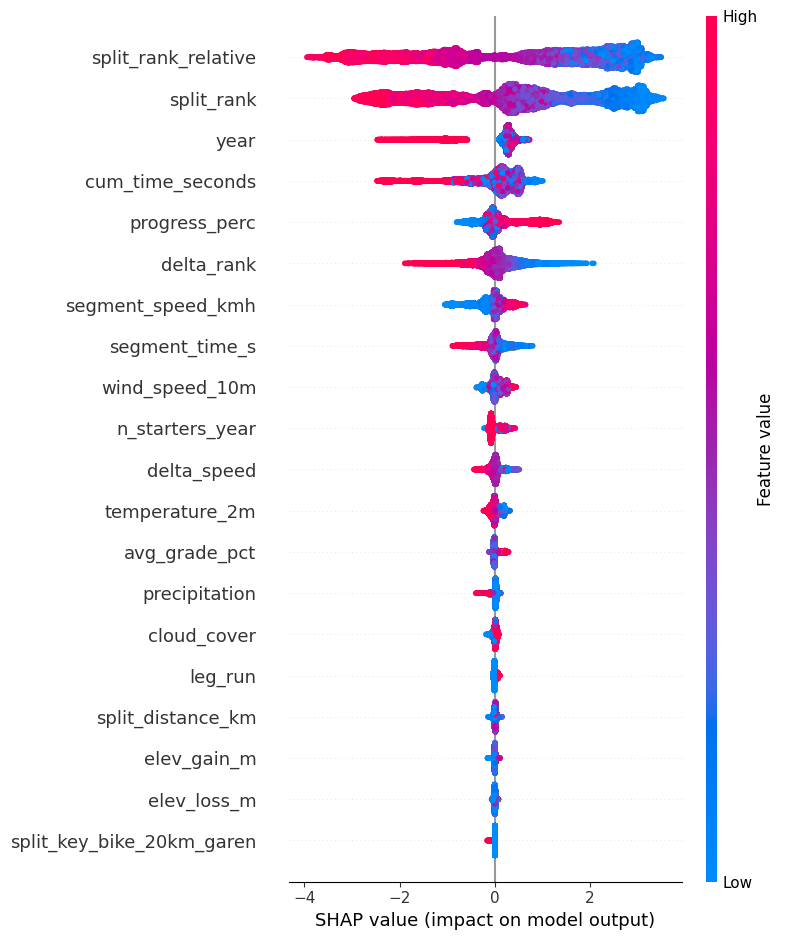

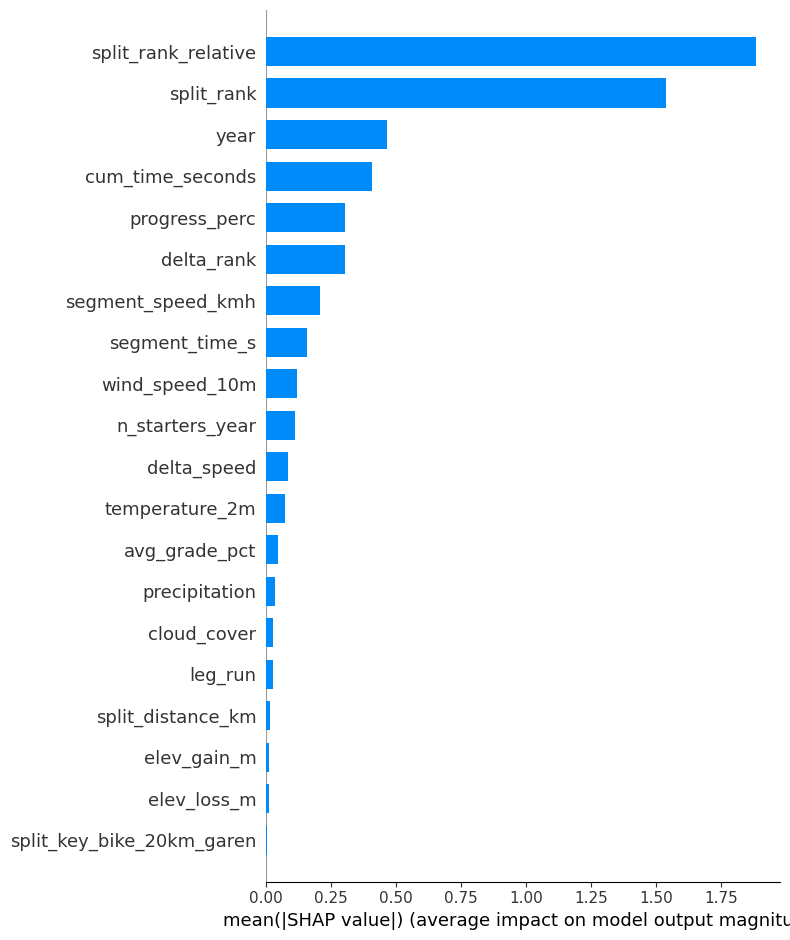

In [17]:
import shap
import numpy as np

# 1) Feature-Namen sauber holen (weil X_train bei dir ein DataFrame ist)
feature_names = list(X_train.columns)

# 2) Trainiertes Modell ist einfach "model"
xgb_fitted = model

# 3) SHAP Explainer + Values
explainer = shap.TreeExplainer(xgb_fitted)
shap_values = explainer.shap_values(X_train)

# 4) Falls SHAP eine Liste zurückgibt (manchmal bei Klassifikation): positive Klasse nehmen
if isinstance(shap_values, list):
    shap_values = shap_values[1]

# 5) Plots
shap.summary_plot(shap_values, X_train, feature_names=feature_names)
shap.summary_plot(shap_values, X_train, feature_names=feature_names, plot_type="bar")


In [24]:
import numpy as np
import pandas as pd

# 1) Alle Dummy-Spalten für split_key holen
split_cols = [c for c in X_train.columns if str(c).startswith("split_key_")]
if len(split_cols) == 0:
    raise ValueError("Keine split_key_* Spalten gefunden.")

# 2) SHAP auf diese Spalten reduzieren
idx = [X_train.columns.get_loc(c) for c in split_cols]
shap_split = shap_values[:, idx]

# 3) mean(|SHAP|) pro split_key Dummy
split_imp = pd.DataFrame({
    "split_key": [c.replace("split_key_", "") for c in split_cols],
    "mean_abs_shap": np.abs(shap_split).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

# 4) Wichtigste Station
print("Wichtigste Station (über split_key-Dummies):", split_imp.iloc[0]["split_key"])
print("mean(|SHAP|):", split_imp.iloc[0]["mean_abs_shap"])

display(split_imp.head(40))


Wichtigste Station (über split_key-Dummies): bike_20km_garen
mean(|SHAP|): 0.005108435


,split_key,mean_abs_shap
8,bike_20km_garen,0.005108
23,run_5km_atraa,0.004728
2,bike_123km_vasstulan,0.003274
1,bike_11km_enter_gamlevegen,0.002894
16,bike_start,0.002860
18,run_15km_tinnsjo,0.001418
13,bike_6km_ovre_eidfjord,0.001162
15,bike_94km_kikut,0.000931
31,transition_1_in,0.000917
11,bike_47km_halne,0.000842


## 9. Finale Fehlklassifikation pro Athlet


In [ ]:
df_final = df_eval.sort_values(["bib", "split_distance_km"])
df_final_last = df_final.groupby("bib").tail(1)

wrong_final = df_final_last[df_final_last["error"] == 1].copy()

print("\nAnzahl final falsch klassifizierter Athleten:", len(wrong_final))
wrong_final.head(20)


Anzahl final falsch klassifizierter Athleten: 23


,bib,year,split_distance_km,split_key,finish_type,y_true,y_proba,y_pred,error
27732,14,2024,180.0,bike_180km_finish,Black,1,0.120548,0,1
17480,28,2021,180.0,bike_180km_finish,White,0,0.778222,1,1
36775,42,2025,142.0,bike_142km_top_imingfjell,Black,1,0.341333,0,1
28708,46,2024,152.0,bike_152km_end_imingfjell,White,0,0.842448,1,1
37382,62,2025,142.0,bike_142km_top_imingfjell,Black,1,0.080027,0,1
37938,79,2025,180.0,bike_180km_finish,Black,1,0.206620,0,1
8825,121,2019,180.0,bike_180km_finish,Black,1,0.320372,0,1
9026,133,2019,180.0,bike_180km_finish,Black,1,0.369221,0,1
39739,138,2025,180.0,bike_180km_finish,White,0,0.678834,1,1
3725,139,2018,180.0,bike_180km_finish,Black,1,0.182998,0,1


## 10. (Optional) Fehler-Rate pro Split-Distanz


In [ ]:
error_rate_by_split = (
    df_eval
    .groupby("split_distance_km")["error"]
    .mean()
    .reset_index()
    .sort_values("split_distance_km")
)

print("\nFehlerrate pro Split-Distanz:")
error_rate_by_split.head(20)


Fehlerrate pro Split-Distanz:


,split_distance_km,error
0,0.00,0.175484
1,3.80,0.259398
2,5.00,0.047059
3,6.00,0.190283
4,10.00,0.033708
5,11.00,0.119048
6,15.00,0.023715
7,16.00,0.152941
8,20.00,0.064583
9,25.00,0.019841
